# skin 집계방식 비교 — wmean vs top vs max vs min

**배경**: `skin_feature_rebuild.ipynb`는 제형의 성분별 descriptor를 **함량(%) 가중평균(wmean)** 하나로만 합성합니다. 팀 리뷰에서 나온 우려:
- 성분 효과가 단순히 비율대로 더해지지 않을 수 있음(소량이어도 강하게 작용하는 성분 존재)
- 여러 성분 간 상호작용이 있을 수 있음
- 최댓값을 가진 성분이 전체 독성을 지배할 수 있음

**이 노트북이 하는 일**: 같은 544개 제형에 대해 4가지 집계방식으로 각각 feature를 만들고, **동일한 평가(StratifiedGroupKFold 5-fold × 5 seed, `skin_addons.ipynb`와 같은 방식)**로 성능을 비교합니다.

| 방식 | 정의 |
|---|---|
| `wmean` | 함량(%) 가중평균 (기존 방식) |
| `top` | 함량이 가장 높은 **주성분 하나**의 descriptor를 그대로 사용 |
| `max` | 각 descriptor별로 **성분들 중 최댓값**(어느 성분에서 나왔든 상관없이 descriptor 축마다 독립적으로 최댓값) |
| `min` | 각 descriptor별로 **성분들 중 최솟값** |

단일성분 제형(334개)은 성분이 하나뿐이라 4가지 방식 전부 **같은 값**이 나옵니다 — 차이는 다성분 제형(210개)에서만 생깁니다.

In [1]:
import numpy as np
import pandas as pd

BASE = r"C:\Users\UserK\학술제\skin irritation"

filtered = pd.read_csv(rf"{BASE}\skin_filtered.csv")
labels = pd.read_csv(rf"{BASE}\skin_formulation_level_with_comp_group.csv")
desc = pd.read_csv(rf"{BASE}\casrn_descriptors.csv").set_index("casrn")
DESC_COLS = [c for c in desc.columns]

known = filtered.dropna(subset=["casrn"]).copy()
known = known.drop_duplicates(subset=["formulation_id", "casrn"], keep="first")
known["has_descriptor"] = known["casrn"].isin(desc.index)
print("고유 제형 수:", known["formulation_id"].nunique())

고유 제형 수: 544


## 1단계 — 4가지 집계 함수 정의

In [2]:
def aggregate_group(g_resolved, method):
    """g_resolved: has_descriptor==True인 성분 행들(한 제형분). method별 descriptor 벡터 반환."""
    d = desc.loc[g_resolved["casrn"]].values
    pct = g_resolved["percent_active_ingredient"].fillna(1.0).values
    if pct.sum() == 0:
        pct = np.ones_like(pct)

    if method == "wmean":
        return (pct[:, None] * d).sum(axis=0) / pct.sum()
    elif method == "top":
        idx = int(np.argmax(pct))
        return d[idx]
    elif method == "max":
        return d.max(axis=0)
    elif method == "min":
        return d.min(axis=0)
    else:
        raise ValueError(method)


def build_final(method):
    rows = []
    for fid, grp in known.groupby("formulation_id"):
        g_resolved = grp[grp["has_descriptor"]]
        row = {"formulation_id": fid}
        if len(g_resolved) > 0:
            vec = aggregate_group(g_resolved, method)
            for col, val in zip(DESC_COLS, vec):
                row[col] = val
        else:
            for col in DESC_COLS:
                row[col] = np.nan
        rows.append(row)
    agg = pd.DataFrame(rows)
    comp_count = known.groupby("formulation_id")["casrn"].nunique().rename("comp_count").reset_index()
    out = agg.merge(comp_count, on="formulation_id", how="left")
    out = out.merge(
        labels[["formulation_id", "final_label", "comp_group_id"]],
        on="formulation_id", how="left", validate="one_to_one",
    )
    out["binary_label"] = out["final_label"].map(lambda x: 1 if x in (1, 2) else 0)
    return out


METHODS = ["wmean", "top", "max", "min"]
finals = {m: build_final(m) for m in METHODS}
print("생성 완료:", {m: finals[m].shape for m in METHODS})

생성 완료: {'wmean': (544, 13), 'top': (544, 13), 'max': (544, 13), 'min': (544, 13)}


## 2단계 — 단일성분 제형은 4방식이 똑같은지 확인(sanity check)

In [3]:
multi = finals["wmean"]["comp_count"] > 1
print("다성분 제형 수(여기서만 방식 차이 발생):", int(multi.sum()))

diff_count = {}
for m in ["top", "max", "min"]:
    same = np.allclose(
        finals["wmean"].loc[~multi, DESC_COLS].values,
        finals[m].loc[~multi, DESC_COLS].values,
        equal_nan=True,
    )
    diff_count[m] = same
print("단일성분 제형에서 wmean과 완전히 동일한가(True여야 정상):", diff_count)

다성분 제형 수(여기서만 방식 차이 발생): 210
단일성분 제형에서 wmean과 완전히 동일한가(True여야 정상): {'top': True, 'max': True, 'min': True}


## 3단계 — 평가 (StratifiedGroupKFold 5-fold × 5 seed)

`skin_addons.ipynb`의 `grouped_cv`와 동일한 방식 — RandomForest, class_weight balanced, 그룹 기준(`comp_group_id`) 분할로 데이터 누수 방지.

In [4]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score


def grouped_cv(df, feature_cols, label="binary_label", n_splits=5, seeds=range(5)):
    ok = df[feature_cols].notna().all(axis=1).values
    X = df.loc[ok, feature_cols].values
    y = df.loc[ok, label].values
    g = df.loc[ok, "comp_group_id"].astype(str).values

    rows = []
    for s in seeds:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=s)
        oof = np.zeros(len(y))
        for tr, te in cv.split(X, y, g):
            assert set(g[tr]).isdisjoint(g[te]), "그룹 누수 발생"
            m = RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample",
                                        min_samples_leaf=2, n_jobs=-1, random_state=s).fit(X[tr], y[tr])
            oof[te] = m.predict_proba(X[te])[:, 1]
        rows.append({"seed": s, "roc_auc": roc_auc_score(y, oof), "pr_auc": average_precision_score(y, oof)})
    return pd.DataFrame(rows), int(ok.sum())


results = []
per_seed = {}
for m in METHODS:
    r, n_used = grouped_cv(finals[m], DESC_COLS)
    per_seed[m] = r
    results.append({"method": m, "n_used": n_used,
                     "ROC-AUC": f"{r.roc_auc.mean():.3f} ± {r.roc_auc.std():.3f}",
                     "PR-AUC": f"{r.pr_auc.mean():.3f} ± {r.pr_auc.std():.3f}",
                     "roc_auc_mean": r.roc_auc.mean(), "pr_auc_mean": r.pr_auc.mean()})

result_table = pd.DataFrame(results).sort_values("pr_auc_mean", ascending=False)
result_table[["method", "n_used", "ROC-AUC", "PR-AUC"]]

,method,n_used,ROC-AUC,PR-AUC
3,min,543,0.765 ± 0.029,0.297 ± 0.038
2,max,543,0.733 ± 0.021,0.220 ± 0.038
1,top,543,0.733 ± 0.023,0.197 ± 0.019
0,wmean,543,0.747 ± 0.041,0.131 ± 0.018


## 4단계 — 결과 시각화

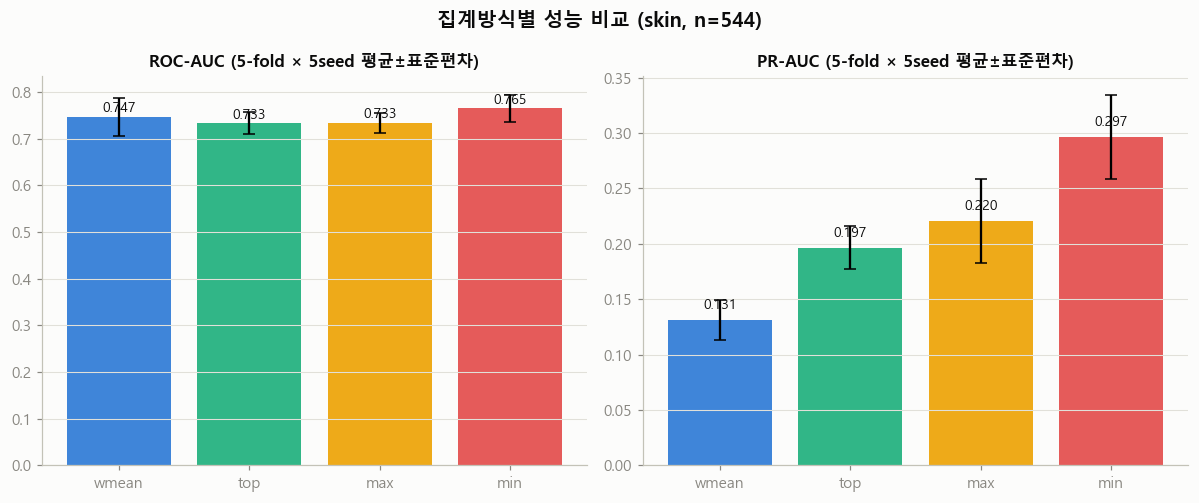

In [5]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

_font_path = r"C:\Windows\Fonts\malgun.ttf"
fm.fontManager.addfont(_font_path)
plt.rcParams["font.family"] = fm.FontProperties(fname=_font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False

SURFACE = "#fcfcfb"; INK = "#0b0b0b"; MUTED = "#898781"; GRID_C = "#e1e0d9"; BASE_C = "#c3c2b7"
COLORS = {"wmean": "#2a78d6", "top": "#1baf7a", "max": "#eda100", "min": "#e34948"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), facecolor=SURFACE)
for ax, metric, title in zip(axes, ["roc_auc", "pr_auc"], ["ROC-AUC", "PR-AUC"]):
    ax.set_facecolor(SURFACE)
    means = [per_seed[m][metric].mean() for m in METHODS]
    stds = [per_seed[m][metric].std() for m in METHODS]
    bars = ax.bar(METHODS, means, yerr=stds, capsize=4,
                  color=[COLORS[m] for m in METHODS], alpha=0.9)
    for b, mean in zip(bars, means):
        ax.text(b.get_x() + b.get_width()/2, mean + 0.01, f"{mean:.3f}", ha="center", fontsize=9, color=INK)
    ax.set_title(f"{title} (5-fold × 5seed 평균±표준편차)", fontsize=11, color=INK, fontweight="bold")
    ax.tick_params(colors=MUTED)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(BASE_C); ax.spines["bottom"].set_color(BASE_C)
    ax.grid(axis="y", color=GRID_C, linewidth=0.7, zorder=0)
fig.suptitle("집계방식별 성능 비교 (skin, n=544)", fontsize=13, color=INK, fontweight="bold")
plt.tight_layout()
plt.show()

## 결론

In [6]:
best_roc = result_table.sort_values("roc_auc_mean", ascending=False).iloc[0]
best_pr = result_table.sort_values("pr_auc_mean", ascending=False).iloc[0]
wmean_row = result_table[result_table["method"] == "wmean"].iloc[0]

print(f"ROC-AUC 1위: {best_roc['method']} ({best_roc['roc_auc_mean']:.3f})")
print(f"PR-AUC  1위: {best_pr['method']} ({best_pr['pr_auc_mean']:.3f})")
print(f"wmean(기존): ROC-AUC {wmean_row['roc_auc_mean']:.3f} / PR-AUC {wmean_row['pr_auc_mean']:.3f}")
print()
print("다성분 제형이 544건 중 210건(39%)뿐이라, 방식 차이의 영향을 받는 샘플 자체가 제한적입니다.")
print("차이가 시드 변동폭(std) 안에 들어온다면, 통계적으로 유의미한 차이라 보기 어렵습니다.")

ROC-AUC 1위: min (0.765)
PR-AUC  1위: min (0.297)
wmean(기존): ROC-AUC 0.747 / PR-AUC 0.131

다성분 제형이 544건 중 210건(39%)뿐이라, 방식 차이의 영향을 받는 샘플 자체가 제한적입니다.
차이가 시드 변동폭(std) 안에 들어온다면, 통계적으로 유의미한 차이라 보기 어렵습니다.


## 한계점

1. **`max`/`min`은 "프랑켄슈타인 벡터"일 수 있음**: descriptor마다 독립적으로 최댓값/최솟값을 골라서, 실제로는 어느 한 성분의 완전한 descriptor 조합이 아닐 수 있습니다(LogP는 성분A, TPSA는 성분B에서 나온 값을 조합). 화학적으로 실재하지 않는 조합이 될 수 있다는 점은 감안해야 합니다.
2. **다성분 제형 210개, 그 중 양성(독성) 라벨은 더 적음** — 방식별 차이를 통계적으로 확실히 가르기엔 표본이 작습니다. 큰 차이가 안 나타났다고 해서 "방식이 중요하지 않다"고 단정하기는 이릅니다.
3. 이 비교는 skin만 대상으로 했습니다 — eye는 다성분 비율이 더 높을 수 있어 결과가 다를 수 있습니다.